In [15]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# -------------------------
# Configuration
# -------------------------
DATA_PATH = Path("dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz")
CKPT_DIR = Path("checkpoints_beta_vae")
CKPT_DIR.mkdir(exist_ok=True)

SEED = 0
BATCH_SIZE = 64

LATENT_DIM = 10
LR = 1e-2

# OUR REPRODUCTION CHOICE: fixed training budget.
MAX_STEPS = 100_000
CHECKPOINT_EVERY = 10_000

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("device:", DEVICE)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

device: cuda


In [16]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np

DATA_PATH = Path(
    "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
)

DSPRITES_URL = (
    "https://github.com/google-deepmind/dsprites-dataset/"
    "raw/refs/heads/master/"
    "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
)

if not DATA_PATH.exists():
    print("Downloading dSprites...")
    urlretrieve(DSPRITES_URL, DATA_PATH)
    print("Download complete:", DATA_PATH.resolve())
else:
    print("Dataset already exists:", DATA_PATH.resolve())

print(f"File size: {DATA_PATH.stat().st_size / 1e6:.1f} MB")

# Load dataset
data = np.load(
    DATA_PATH,
    allow_pickle=True,
    encoding="latin1"
)

imgs = data["imgs"]
latents_classes = data["latents_classes"]

print("images:", imgs.shape, imgs.dtype)
print("latent classes:", latents_classes.shape)
print("keys:", list(data.keys()))

assert imgs.shape == (737280, 64, 64)
assert latents_classes.shape == (737280, 6)

print("dSprites loaded successfully.")

# Standard dSprites factor ordering:
# color, shape, scale, orientation, posX, posY
FACTOR_NAMES = [
    "color", "shape", "scale",
    "rotation", "posX", "posY"
]

for i, name in enumerate(FACTOR_NAMES):
    print(name, np.unique(latents_classes[:, i]).size)


class DSpritesDataset(Dataset):
    def __init__(self, imgs):
        self.imgs = imgs

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        # Paper input is flattened 64x64 binary image.
        x = torch.from_numpy(
            self.imgs[idx].astype(np.float32)
        ).view(-1)

        return x


dataset = DSpritesDataset(imgs)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
)

Download complete: C:\Users\lukew\dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
File size: 19.3 MB
images: (737280, 64, 64) uint8
latent classes: (737280, 6)
keys: ['metadata', 'imgs', 'latents_classes', 'latents_values']
dSprites loaded successfully.
color 1
shape 3
scale 6
rotation 40
posX 32
posY 32


In [17]:
class BetaVAE(nn.Module):
    def __init__(self, latent_dim=10):
        super().__init__()

        # Encoder: FC 1200, 1200; ReLU
        self.enc1 = nn.Linear(4096, 1200)
        self.enc2 = nn.Linear(1200, 1200)

        self.fc_mu = nn.Linear(1200, latent_dim)
        self.fc_logvar = nn.Linear(1200, latent_dim)

        # Decoder: FC 1200, 1200, 1200, 4096; Tanh
        self.dec1 = nn.Linear(latent_dim, 1200)
        self.dec2 = nn.Linear(1200, 1200)
        self.dec3 = nn.Linear(1200, 1200)

        # Bernoulli logits
        self.dec_out = nn.Linear(1200, 4096)

    def encode(self, x):
        h = F.relu(self.enc1(x))
        h = F.relu(self.enc2(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode_logits(self, z):
        h = torch.tanh(self.dec1(z))
        h = torch.tanh(self.dec2(h))
        h = torch.tanh(self.dec3(h))
        return self.dec_out(h)

    def decode(self, z):
        return torch.sigmoid(self.decode_logits(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        logits = self.decode_logits(z)
        return logits, mu, logvar

In [18]:
def beta_vae_loss(x, logits, mu, logvar, beta):
    # Bernoulli negative log likelihood.
    #
    # IMPORTANT: sum over 4096 pixels, then mean over batch.
    # Do NOT use mean over pixels, because that changes the
    # effective scale of beta.

    recon_per_example = F.binary_cross_entropy_with_logits(
        logits,
        x,
        reduction="none"
    ).sum(dim=1)

    kl_per_example = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    loss = (
        recon_per_example + beta * kl_per_example
    ).mean()

    return (
        loss,
        recon_per_example.mean(),
        kl_per_example.mean()
    )

In [19]:
seed_everything()

test_model = BetaVAE(LATENT_DIM).to(DEVICE)

x = next(iter(train_loader)).to(DEVICE)

logits, mu, logvar = test_model(x)

print("input:", x.shape)
print("output:", logits.shape)
print("mu:", mu.shape)
print("logvar:", logvar.shape)

assert x.shape[1] == 4096
assert logits.shape == x.shape
assert mu.shape[1] == 10

# Reconstruction image dimensions
recon = torch.sigmoid(logits).view(-1, 1, 64, 64)
print("reconstruction:", recon.shape)

assert recon.shape[1:] == (1, 64, 64)

# Finite loss + backward
loss, recon_loss, kl = beta_vae_loss(
    x, logits, mu, logvar, beta=4
)

print(
    "loss =", loss.item(),
    "recon =", recon_loss.item(),
    "KL =", kl.item()
)

assert torch.isfinite(loss)

test_model.zero_grad()
loss.backward()

assert any(
    p.grad is not None and torch.isfinite(p.grad).all()
    for p in test_model.parameters()
)

print("Backward pass: OK")

input: torch.Size([64, 4096])
output: torch.Size([64, 4096])
mu: torch.Size([64, 10])
logvar: torch.Size([64, 10])
reconstruction: torch.Size([64, 1, 64, 64])
loss = 2841.0244140625 recon = 2841.01025390625 KL = 0.0035376674495637417
Backward pass: OK


mean first 10: 6973.558807373047
mean last 10:  443.31035766601565


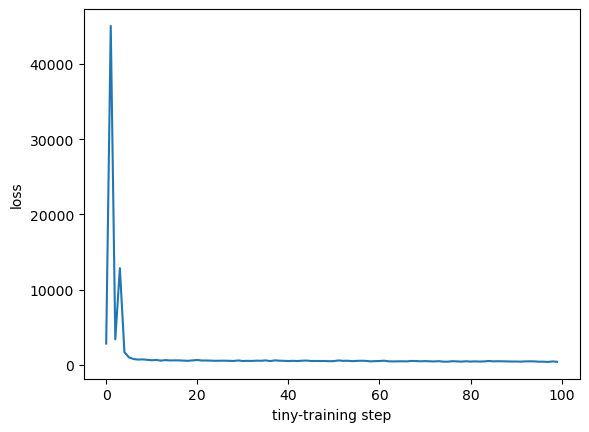

In [20]:
seed_everything()

tiny_model = BetaVAE(LATENT_DIM).to(DEVICE)
tiny_opt = torch.optim.Adagrad(
    tiny_model.parameters(),
    lr=LR
)

tiny_iter = iter(train_loader)
tiny_losses = []

for step in range(100):
    try:
        x = next(tiny_iter)
    except StopIteration:
        tiny_iter = iter(train_loader)
        x = next(tiny_iter)

    x = x.to(DEVICE)

    tiny_opt.zero_grad()

    logits, mu, logvar = tiny_model(x)

    loss, _, _ = beta_vae_loss(
        x, logits, mu, logvar, beta=4
    )

    loss.backward()
    tiny_opt.step()

    tiny_losses.append(loss.item())

print("mean first 10:", np.mean(tiny_losses[:10]))
print("mean last 10: ", np.mean(tiny_losses[-10:]))

plt.plot(tiny_losses)
plt.xlabel("tiny-training step")
plt.ylabel("loss")
plt.show()

In [21]:
del tiny_model, tiny_opt
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [22]:
def save_checkpoint(model, optimizer, beta, step, path):
    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "beta": beta,
            "step": step,
            "seed": SEED,
        },
        path
    )


def load_checkpoint(model, optimizer, path):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(ckpt["model"])

    if optimizer is not None:
        optimizer.load_state_dict(ckpt["optimizer"])

    return ckpt


def train_beta_vae(
    beta,
    max_steps=MAX_STEPS,
    checkpoint_every=CHECKPOINT_EVERY,
):
    seed_everything(SEED)

    model = BetaVAE(LATENT_DIM).to(DEVICE)

    optimizer = torch.optim.Adagrad(
        model.parameters(),
        lr=LR
    )

    final_path = CKPT_DIR / f"beta_{beta:g}_final.pt"

    # Never retrain unnecessarily.
    if final_path.exists():
        print("Loading existing:", final_path)
        load_checkpoint(model, None, final_path)
        model.eval()
        return model

    step = 0
    loader_iter = iter(train_loader)

    running_loss = []
    running_recon = []
    running_kl = []

    model.train()

    while step < max_steps:
        try:
            x = next(loader_iter)
        except StopIteration:
            loader_iter = iter(train_loader)
            x = next(loader_iter)

        x = x.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        logits, mu, logvar = model(x)

        loss, recon, kl = beta_vae_loss(
            x, logits, mu, logvar, beta
        )

        loss.backward()
        optimizer.step()

        step += 1

        running_loss.append(loss.item())
        running_recon.append(recon.item())
        running_kl.append(kl.item())

        if step % 1000 == 0:
            print(
                f"beta={beta} "
                f"step={step:6d} | "
                f"loss={np.mean(running_loss[-1000:]):.2f} | "
                f"recon={np.mean(running_recon[-1000:]):.2f} | "
                f"KL={np.mean(running_kl[-1000:]):.2f}"
            )

        if step % checkpoint_every == 0:
            path = CKPT_DIR / f"beta_{beta:g}_step_{step}.pt"

            save_checkpoint(
                model,
                optimizer,
                beta,
                step,
                path
            )

            print("saved:", path)

    save_checkpoint(
        model,
        optimizer,
        beta,
        step,
        final_path
    )

    print("saved final:", final_path)

    model.eval()
    return model

In [23]:
model_b1 = train_beta_vae(beta=1)

beta=1 step=  1000 | loss=262.18 | recon=232.00 | KL=30.18
beta=1 step=  2000 | loss=131.86 | recon=113.10 | KL=18.76
beta=1 step=  3000 | loss=120.11 | recon=103.02 | KL=17.10
beta=1 step=  4000 | loss=114.82 | recon=98.30 | KL=16.52
beta=1 step=  5000 | loss=111.67 | recon=95.38 | KL=16.29
beta=1 step=  6000 | loss=109.62 | recon=93.50 | KL=16.12
beta=1 step=  7000 | loss=108.08 | recon=92.07 | KL=16.01
beta=1 step=  8000 | loss=105.88 | recon=89.91 | KL=15.97
beta=1 step=  9000 | loss=103.52 | recon=87.42 | KL=16.10
beta=1 step= 10000 | loss=100.70 | recon=84.43 | KL=16.27
saved: checkpoints_beta_vae\beta_1_step_10000.pt
beta=1 step= 11000 | loss=98.57 | recon=82.17 | KL=16.40
beta=1 step= 12000 | loss=97.06 | recon=80.60 | KL=16.46
beta=1 step= 13000 | loss=95.88 | recon=79.32 | KL=16.56
beta=1 step= 14000 | loss=95.25 | recon=78.66 | KL=16.58
beta=1 step= 15000 | loss=94.49 | recon=77.86 | KL=16.63
beta=1 step= 16000 | loss=94.28 | recon=77.61 | KL=16.67
beta=1 step= 17000 | loss=

In [24]:
model_b4 = train_beta_vae(beta=4)

beta=4 step=  1000 | loss=324.73 | recon=245.48 | KL=19.81
beta=4 step=  2000 | loss=163.20 | recon=125.03 | KL=9.54
beta=4 step=  3000 | loss=153.98 | recon=117.41 | KL=9.14
beta=4 step=  4000 | loss=150.63 | recon=114.75 | KL=8.97
beta=4 step=  5000 | loss=148.10 | recon=112.52 | KL=8.89
beta=4 step=  6000 | loss=146.64 | recon=111.16 | KL=8.87
beta=4 step=  7000 | loss=145.35 | recon=109.81 | KL=8.89
beta=4 step=  8000 | loss=143.94 | recon=108.17 | KL=8.94
beta=4 step=  9000 | loss=142.36 | recon=106.30 | KL=9.02
beta=4 step= 10000 | loss=140.97 | recon=104.46 | KL=9.13
saved: checkpoints_beta_vae\beta_4_step_10000.pt
beta=4 step= 11000 | loss=139.31 | recon=102.37 | KL=9.23
beta=4 step= 12000 | loss=138.25 | recon=101.06 | KL=9.30
beta=4 step= 13000 | loss=137.42 | recon=99.88 | KL=9.39
beta=4 step= 14000 | loss=136.82 | recon=99.14 | KL=9.42
beta=4 step= 15000 | loss=136.28 | recon=98.47 | KL=9.45
beta=4 step= 16000 | loss=136.54 | recon=98.57 | KL=9.49
beta=4 step= 17000 | loss=

In [25]:
model_b1 = BetaVAE(LATENT_DIM).to(DEVICE)
model_b4 = BetaVAE(LATENT_DIM).to(DEVICE)

load_checkpoint(
    model_b1,
    None,
    CKPT_DIR / "beta_1_final.pt"
)

load_checkpoint(
    model_b4,
    None,
    CKPT_DIR / "beta_4_final.pt"
)

model_b1.eval()
model_b4.eval()

print("Both models loaded.")

Both models loaded.


In [26]:
@torch.no_grad()
def infer_all(model, batch_size=512):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    mus = []
    variances = []
    kls = []

    model.eval()

    for x in loader:
        x = x.to(DEVICE)

        mu, logvar = model.encode(x)

        var = torch.exp(logvar)

        # KL separately for every latent dimension
        kl_dim = -0.5 * (
            1 + logvar - mu.pow(2) - var
        )

        mus.append(mu.cpu())
        variances.append(var.cpu())
        kls.append(kl_dim.cpu())

    return (
        torch.cat(mus).numpy(),
        torch.cat(variances).numpy(),
        torch.cat(kls).numpy()
    )


mu_b1, var_b1, kl_b1 = infer_all(model_b1)
mu_b4, var_b4, kl_b4 = infer_all(model_b4)

print(mu_b1.shape, mu_b4.shape)

(737280, 10) (737280, 10)


In [27]:
def latent_statistics(var, kl):
    mean_var = var.mean(axis=0)
    mean_kl = kl.mean(axis=0)

    # OUR REPRODUCTION CHOICE:
    # ascending learned posterior variance.
    order = np.argsort(mean_var)

    return mean_var, mean_kl, order


varmean_b1, klmean_b1, order_b1 = latent_statistics(
    var_b1, kl_b1
)

varmean_b4, klmean_b4, order_b4 = latent_statistics(
    var_b4, kl_b4
)

print("β=1 ordering:", order_b1)
print("β=1 variance:", varmean_b1[order_b1])
print("β=1 KL:", klmean_b1[order_b1])

print()
print("β=4 ordering:", order_b4)
print("β=4 variance:", varmean_b4[order_b4])
print("β=4 KL:", klmean_b4[order_b4])

β=1 ordering: [3 5 7 0 9 8 1 2 6 4]
β=1 variance: [0.0009912  0.00132633 0.00362029 0.00842024 0.01164966 0.01793648
 0.93214935 0.93621445 0.936417   0.94432235]
β=1 KL: [3.6086433e+00 3.4343910e+00 3.2603886e+00 2.7165797e+00 2.4333150e+00
 2.1298921e+00 2.4665126e-03 2.6550216e-03 2.3867006e-03 1.7888464e-03]

β=4 ordering: [9 3 1 5 2 0 7 8 6 4]
β=4 variance: [0.00200932 0.00325394 0.01150424 0.11964957 0.18041933 0.98718464
 0.9877917  0.98829514 0.9890719  0.9893619 ]
β=4 KL: [3.3007877e+00 3.1393037e+00 2.3065352e+00 1.1889397e+00 9.3492222e-01
 3.2289044e-04 2.7642210e-04 3.1843039e-04 3.0285359e-04 2.6601204e-04]


In [28]:
shape = latents_classes[:, 1]
scale = latents_classes[:, 2]
rotation = latents_classes[:, 3]
pos_x = latents_classes[:, 4]
pos_y = latents_classes[:, 5]

SHAPES = np.unique(shape)
SCALES = np.unique(scale)
ROTATIONS = np.unique(rotation)
POS_X = np.unique(pos_x)
POS_Y = np.unique(pos_y)

print(
    len(SHAPES),
    len(SCALES),
    len(ROTATIONS),
    len(POS_X),
    len(POS_Y)
)


def compute_factor_responses(mu):
    D = mu.shape[1]

    # position: [latent, y, x]
    position_response = np.zeros(
        (D, len(POS_Y), len(POS_X)),
        dtype=np.float32
    )

    for yi, y in enumerate(POS_Y):
        for xi, x in enumerate(POS_X):
            mask = (pos_x == x) & (pos_y == y)
            position_response[:, yi, xi] = mu[mask].mean(axis=0)

    # scale: separate curve for each object identity
    # [latent, shape, scale]
    scale_response = np.zeros(
        (D, len(SHAPES), len(SCALES)),
        dtype=np.float32
    )

    for si, s in enumerate(SHAPES):
        for qi, q in enumerate(SCALES):
            mask = (shape == s) & (scale == q)
            scale_response[:, si, qi] = mu[mask].mean(axis=0)

    # rotation: separate curve for each object identity
    # [latent, shape, rotation]
    rotation_response = np.zeros(
        (D, len(SHAPES), len(ROTATIONS)),
        dtype=np.float32
    )

    for si, s in enumerate(SHAPES):
        for ri, r in enumerate(ROTATIONS):
            mask = (shape == s) & (rotation == r)
            rotation_response[:, si, ri] = mu[mask].mean(axis=0)

    return {
        "position": position_response,
        "scale": scale_response,
        "rotation": rotation_response,
    }


responses_b1 = compute_factor_responses(mu_b1)
responses_b4 = compute_factor_responses(mu_b4)

3 6 40 32 32


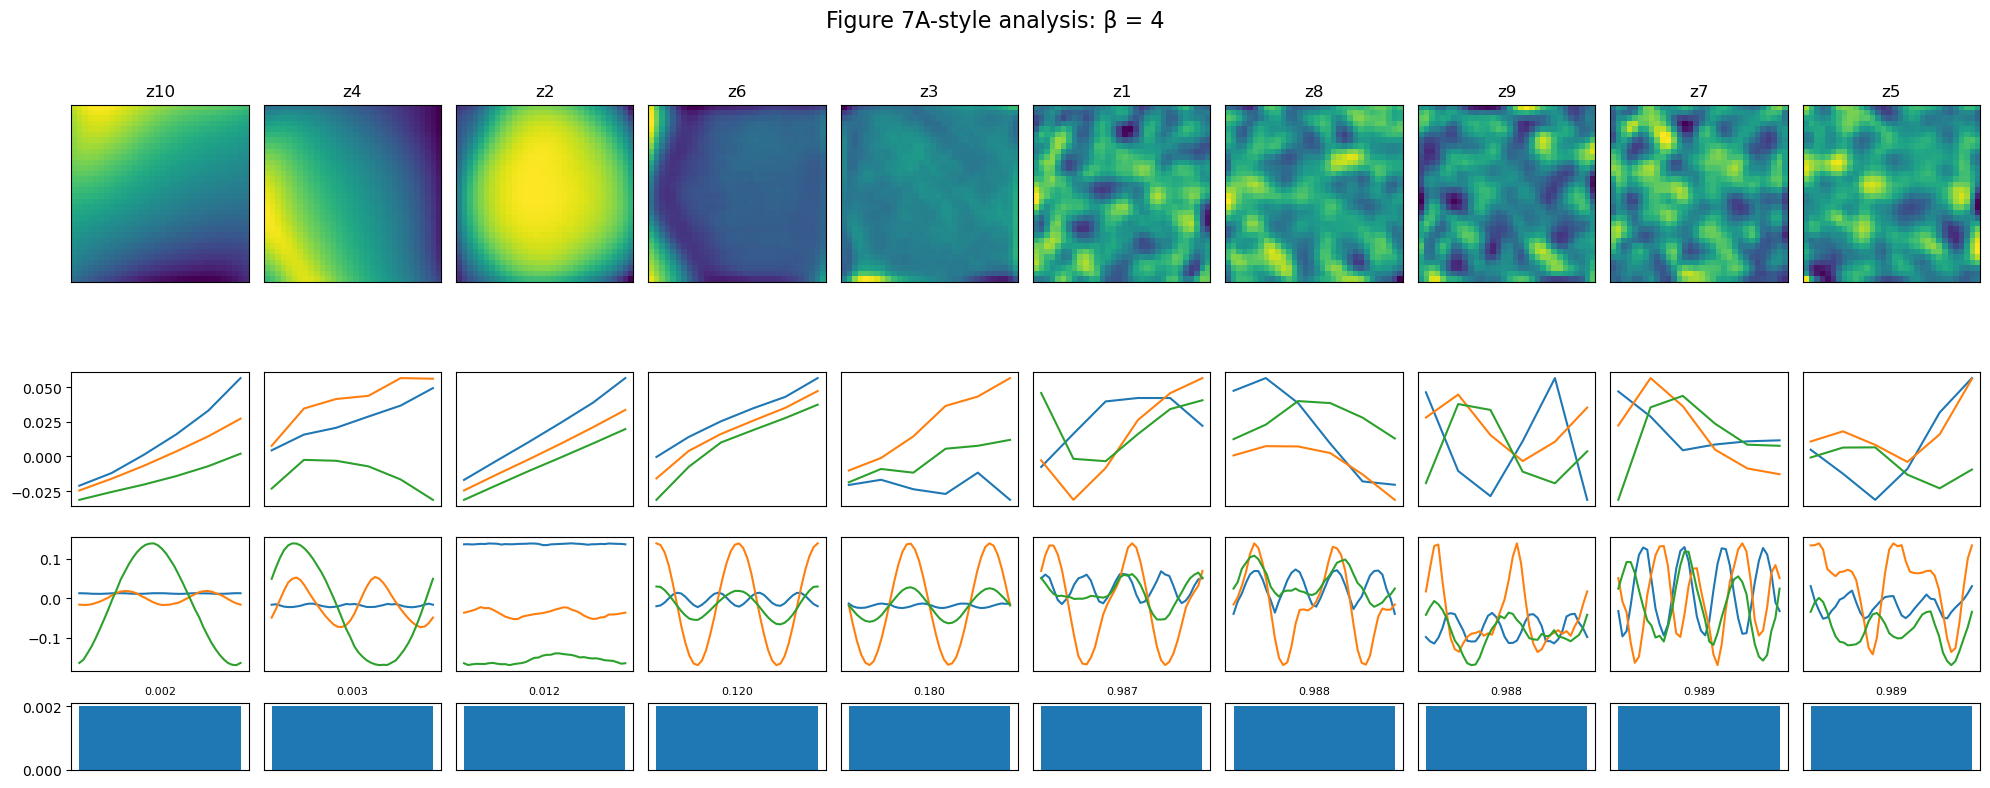

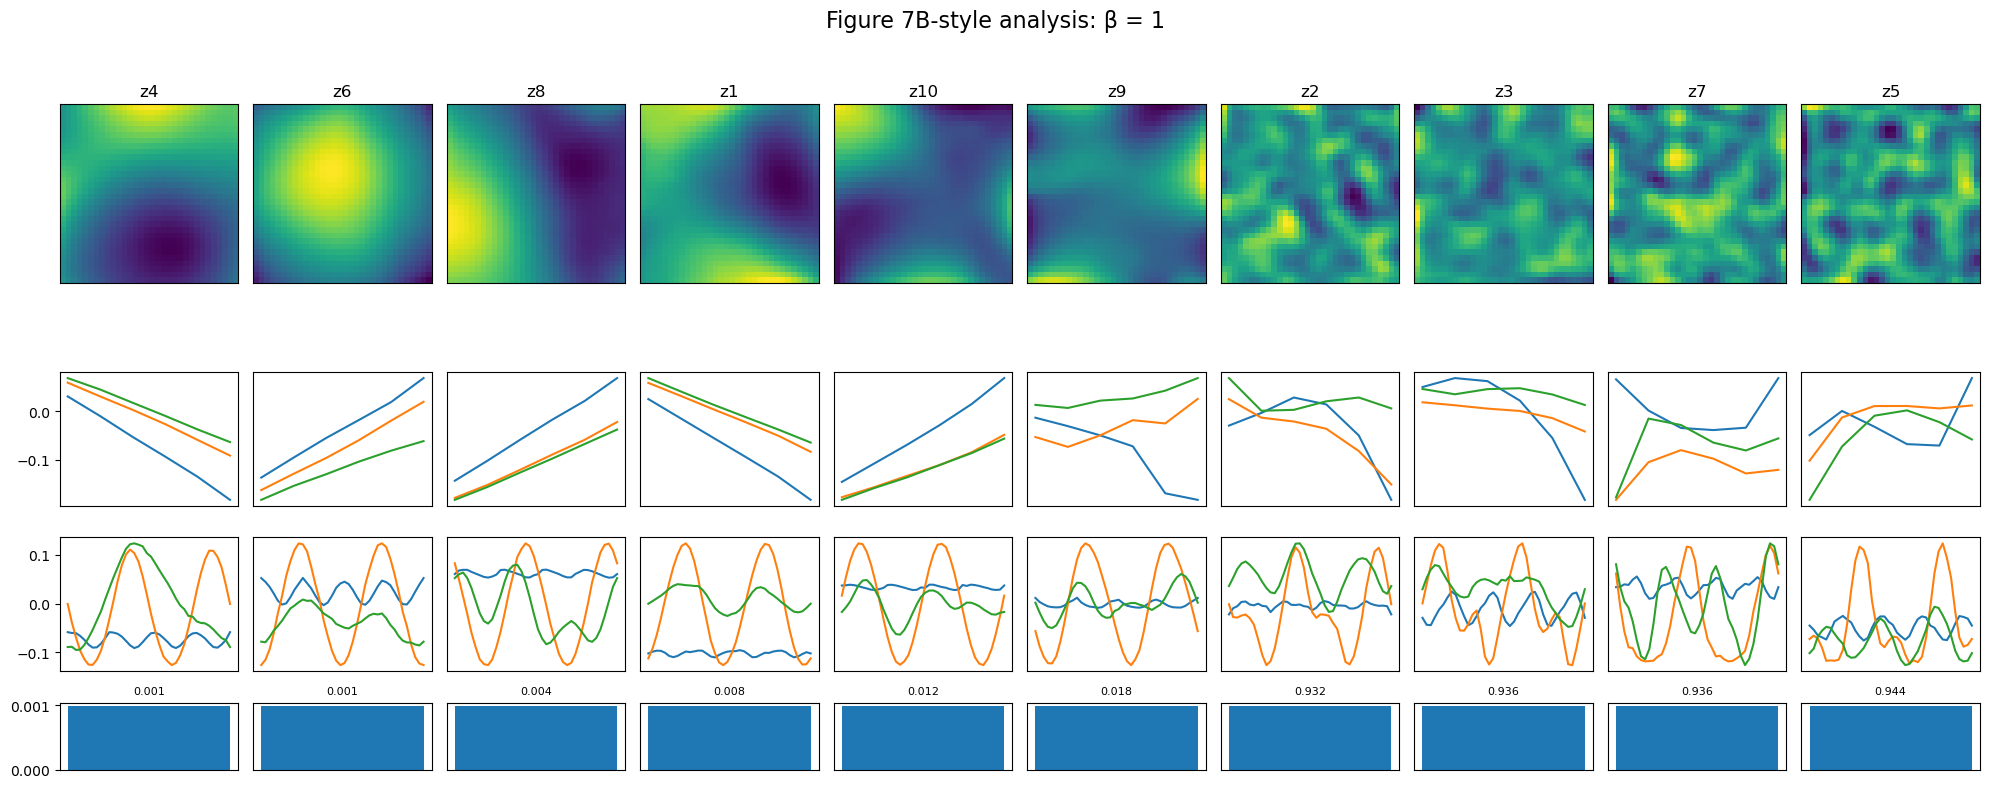

In [29]:
SHAPE_NAMES = ["square", "oval", "heart"]


def plot_factor_analysis(
    responses,
    mean_var,
    order,
    title
):
    D = len(order)

    fig = plt.figure(
        figsize=(2.0 * D, 8)
    )

    gs = fig.add_gridspec(
        4,
        D,
        height_ratios=[2.2, 1, 1, 0.5]
    )

    for col, latent in enumerate(order):
        # Position heatmap
        ax = fig.add_subplot(gs[0, col])

        im = ax.imshow(
            responses["position"][latent],
            origin="lower",
            aspect="equal"
        )

        ax.set_title(f"z{latent + 1}")
        ax.set_xticks([])
        ax.set_yticks([])

        # Scale
        ax = fig.add_subplot(gs[1, col])

        for s in range(len(SHAPES)):
            ax.plot(
                SCALES,
                responses["scale"][latent, s],
                label=SHAPE_NAMES[s]
            )

        ax.set_xticks([])
        if col != 0:
            ax.set_yticks([])

        # Rotation
        ax = fig.add_subplot(gs[2, col])

        for s in range(len(SHAPES)):
            ax.plot(
                ROTATIONS,
                responses["rotation"][latent, s]
            )

        ax.set_xticks([])
        if col != 0:
            ax.set_yticks([])

        # Posterior variance
        ax = fig.add_subplot(gs[3, col])

        ax.bar([0], [mean_var[latent]])
        ax.set_xticks([])
        ax.set_title(
            f"{mean_var[latent]:.3f}",
            fontsize=8
        )

        if col != 0:
            ax.set_yticks([])

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


plot_factor_analysis(
    responses_b4,
    varmean_b4,
    order_b4,
    "Figure 7A-style analysis: β = 4"
)

plot_factor_analysis(
    responses_b1,
    varmean_b1,
    order_b1,
    "Figure 7B-style analysis: β = 1"
)

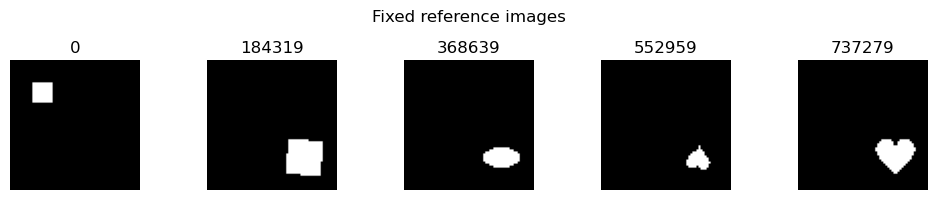

In [30]:
# OUR REPRODUCTION CHOICE:
# deterministic examples spread across the dataset.
REFERENCE_INDICES = np.linspace(
    0,
    len(dataset) - 1,
    5,
    dtype=int
)

fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for ax, idx in zip(axes, REFERENCE_INDICES):
    ax.imshow(imgs[idx], cmap="gray")
    ax.axis("off")
    ax.set_title(str(idx))

plt.suptitle("Fixed reference images")
plt.tight_layout()
plt.show()

In [31]:
# Paper: +/- 3 standard deviations around N(0, I).
# OUR REPRODUCTION CHOICE: seven displayed values.
TRAVERSAL_VALUES = torch.linspace(-3, 3, 7)


@torch.no_grad()
def latent_traversal(
    model,
    image_index,
    latent_index,
    traversal_values=TRAVERSAL_VALUES
):
    x = torch.from_numpy(
        imgs[image_index].astype(np.float32)
    ).view(1, -1).to(DEVICE)

    # OUR REPRODUCTION CHOICE:
    # posterior mean rather than a stochastic posterior sample.
    mu, _ = model.encode(x)

    z_base = mu.squeeze(0)

    outputs = []

    for value in traversal_values:
        z = z_base.clone()

        # Only one latent changes.
        z[latent_index] = value.to(DEVICE)

        recon = model.decode(
            z.unsqueeze(0)
        ).view(64, 64)

        outputs.append(recon.cpu().numpy())

    return np.stack(outputs)

In [32]:
def plot_traversal_grid(
    model,
    latent_order,
    title,
    reference_indices=REFERENCE_INDICES,
    traversal_values=TRAVERSAL_VALUES
):
    n_refs = len(reference_indices)
    n_latents = len(latent_order)
    n_values = len(traversal_values)

    fig, axes = plt.subplots(
        n_refs,
        n_latents * n_values,
        figsize=(n_latents * n_values * 0.65,
                 n_refs * 0.8),
        squeeze=False
    )

    for row, image_idx in enumerate(reference_indices):
        for group, latent_idx in enumerate(latent_order):
            traversal = latent_traversal(
                model,
                image_idx,
                latent_idx,
                traversal_values
            )

            for k in range(n_values):
                ax = axes[row, group * n_values + k]

                ax.imshow(
                    traversal[k],
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )

                ax.axis("off")

                if row == 0 and k == n_values // 2:
                    ax.set_title(
                        f"z{latent_idx + 1}",
                        fontsize=8
                    )

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

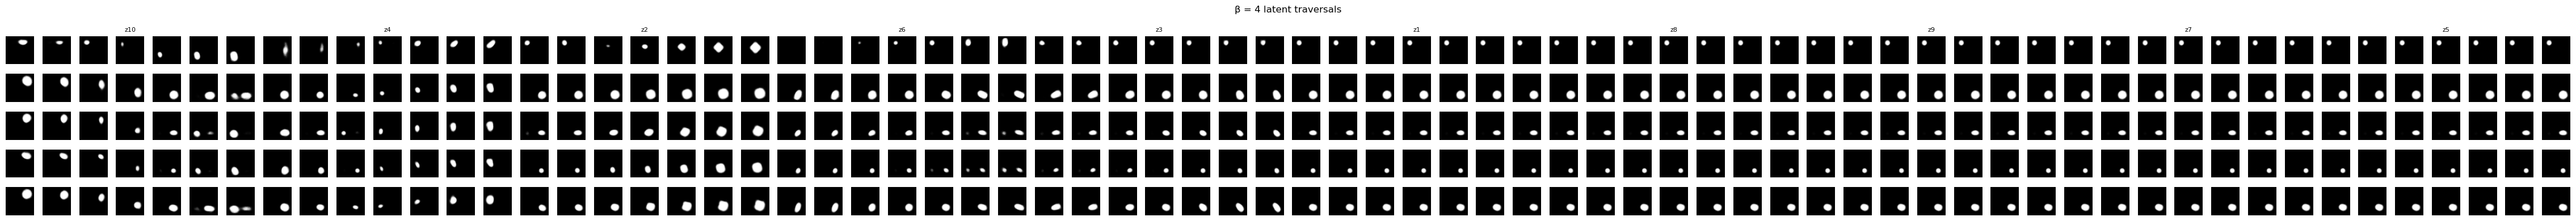

In [33]:
plot_traversal_grid(
    model_b4,
    order_b4,
    "β = 4 latent traversals"
)

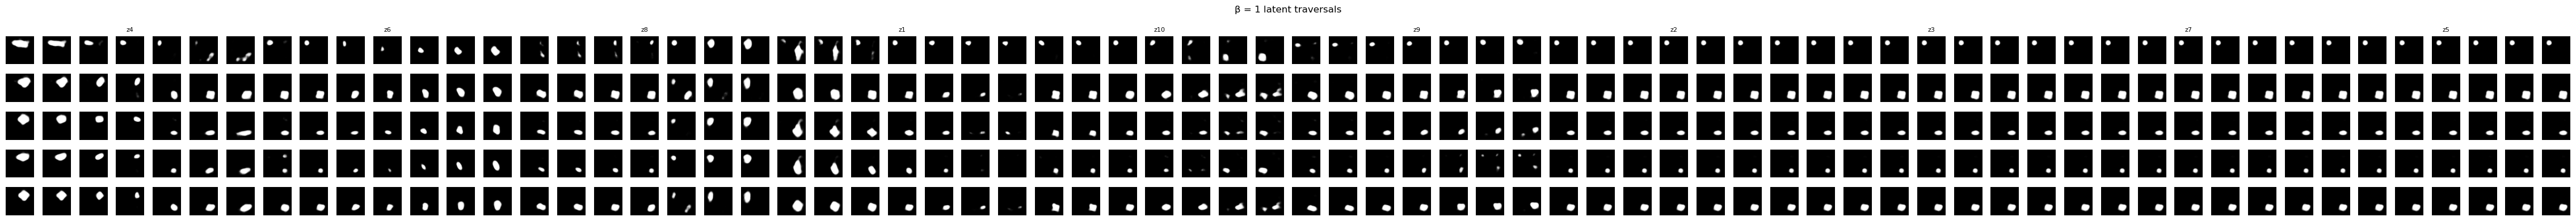

In [34]:
plot_traversal_grid(
    model_b1,
    order_b1,
    "β = 1 latent traversals"
)

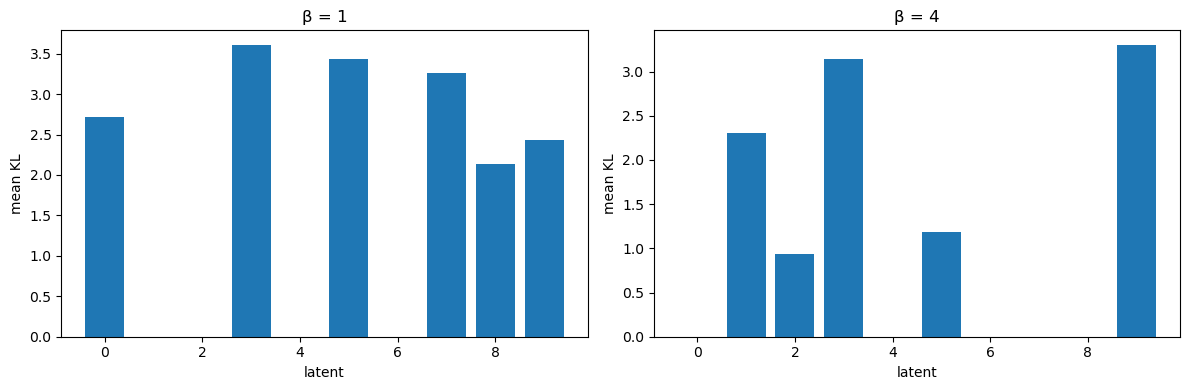

In [35]:
def plot_kl_comparison():
    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )

    axes[0].bar(
        np.arange(LATENT_DIM),
        klmean_b1
    )

    axes[0].set_title("β = 1")
    axes[0].set_xlabel("latent")
    axes[0].set_ylabel("mean KL")

    axes[1].bar(
        np.arange(LATENT_DIM),
        klmean_b4
    )

    axes[1].set_title("β = 4")
    axes[1].set_xlabel("latent")
    axes[1].set_ylabel("mean KL")

    plt.tight_layout()
    plt.show()


plot_kl_comparison()

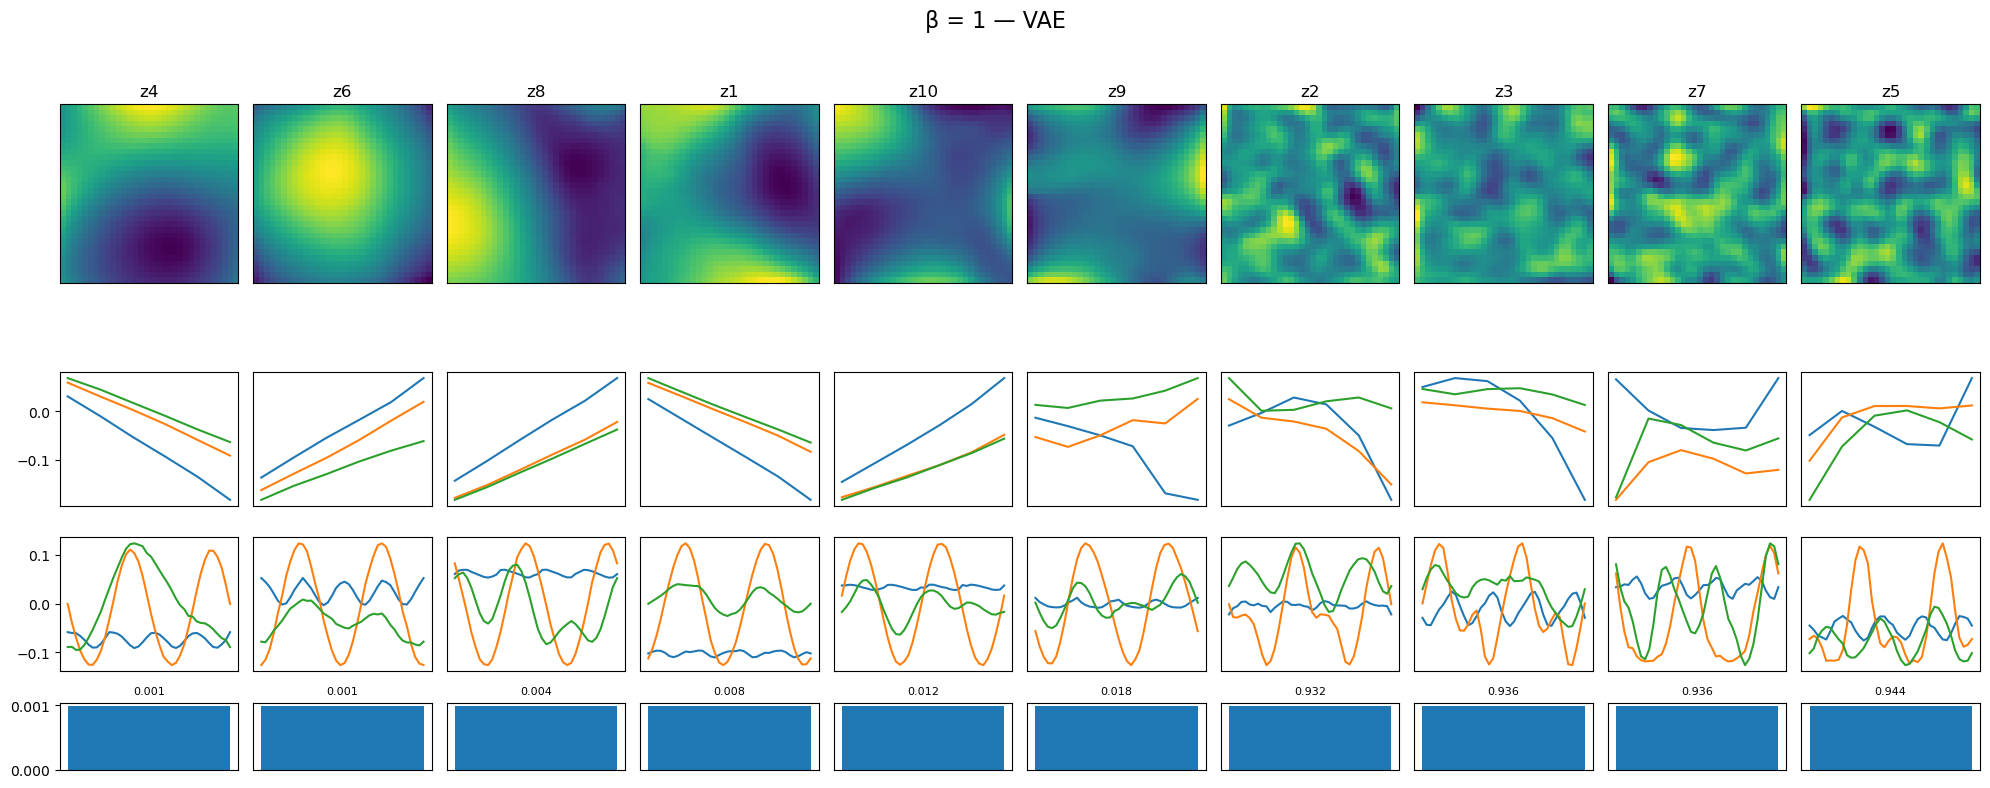

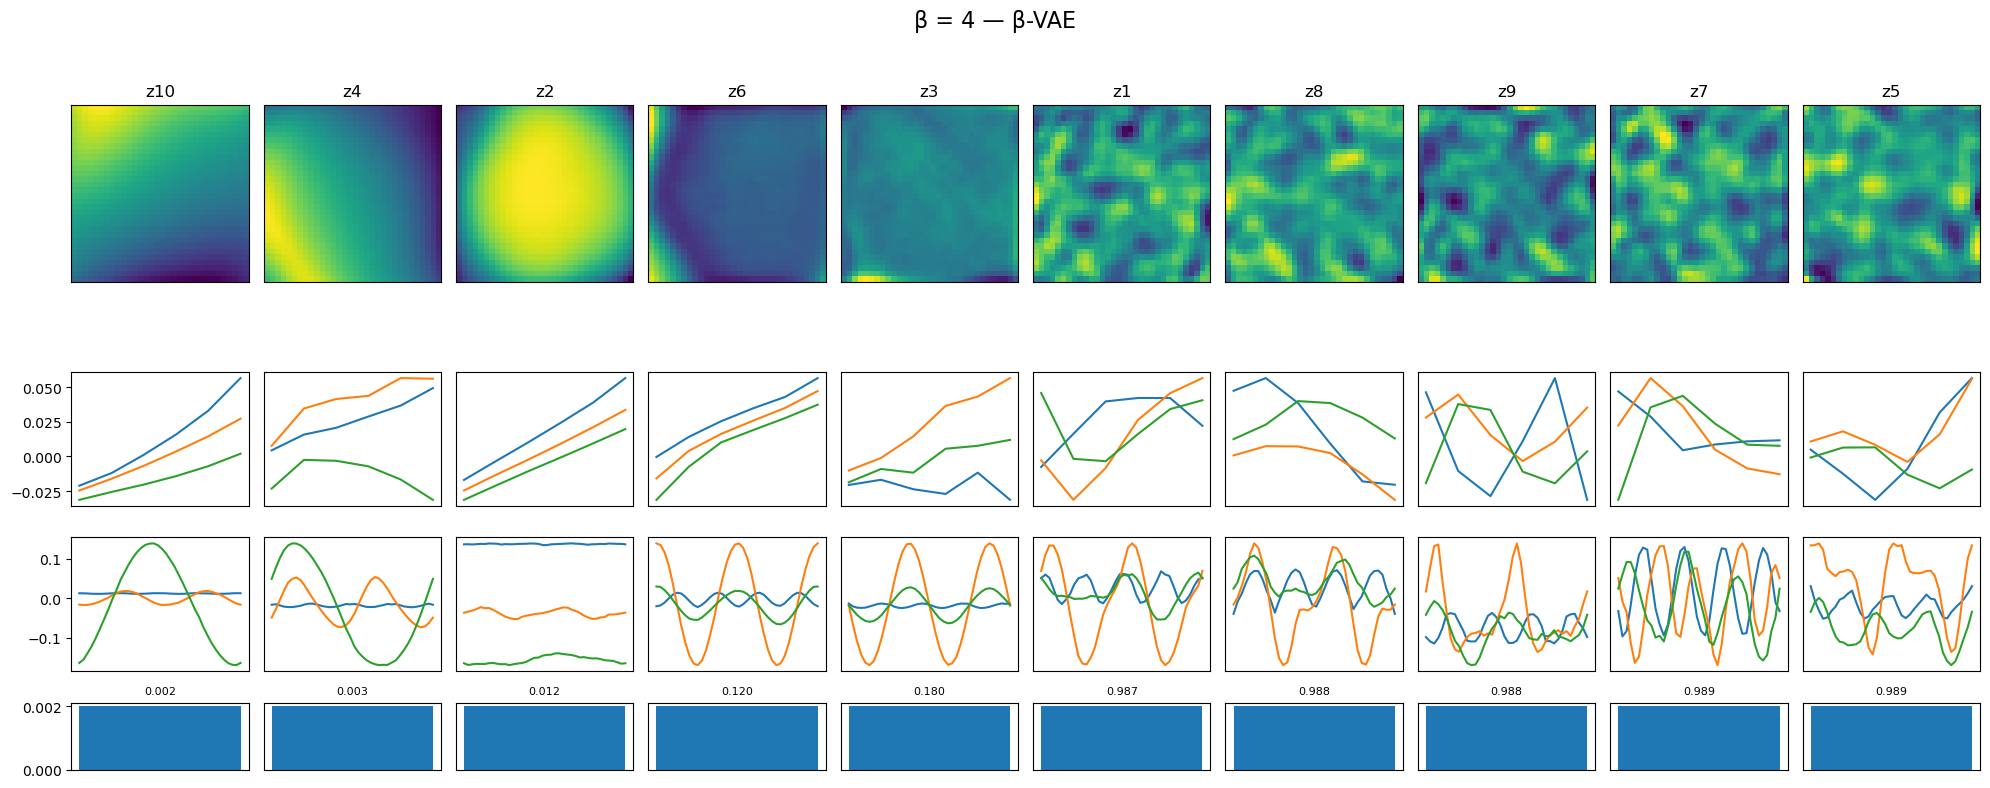

In [36]:
plot_factor_analysis(
    responses_b1,
    varmean_b1,
    order_b1,
    "β = 1 — VAE"
)

plot_factor_analysis(
    responses_b4,
    varmean_b4,
    order_b4,
    "β = 4 — β-VAE"
)